# Where the STT4SG-350 speakers live

Built by `uv run --extra geo python scripts/build_zip_geo.py <data_dir>`: `zip_municipality.csv` maps
each speaker zip code to its municipality with coordinates, `geo.gpkg` holds the polygons (LV95).

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("/Users/felix/PhD/02_Edu/maloney/data/stt4sg-350_v2-1")

table = pd.read_csv(DATA_DIR / "zip_municipality.csv", dtype={"zipcode": str})
munis = gpd.read_file(DATA_DIR / "geo.gpkg", layer="municipalities")
zips = gpd.read_file(DATA_DIR / "geo.gpkg", layer="zips")
switzerland = gpd.GeoSeries([munis.union_all()], crs=munis.crs)
table.head()

,zipcode,bfs_nr,municipality,muni_share,canton,canton_tsv,dialect_region,n_dialect_regions,n_speakers,n_clips,hours,zip_E,zip_N,zip_lat,zip_lon,muni_E,muni_N,muni_lat,muni_lon
0,2560,743,Nidau,90.1,BE,BE,Bern,1,1,329,0.491,2584997.0,1219284.1,47.124372,7.240910,2584997.0,1219284.1,47.124372,7.240910
1,3007,351,Bern,99.5,BE,BE,Bern,1,1,331,0.369,2599644.5,1198608.1,46.938562,7.433964,2597433.2,1199522.0,46.946778,7.404917
2,3027,351,Bern,100.0,BE,BE,Bern,1,1,318,0.475,2595873.9,1200187.0,46.952752,7.384430,2597433.2,1199522.0,46.946778,7.404917
3,3053,546,Münchenbuchsee,98.9,BE,BE,Bern,1,1,163,0.194,2600337.0,1208230.6,47.025118,7.443065,2600337.0,1208230.6,47.025118,7.443065
4,3067,359,Vechigen,99.8,BE,BE,Bern,1,1,353,0.603,2608618.8,1201143.0,46.961309,7.551872,2610135.7,1201540.8,46.964866,7.571810


In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# One fixed colour per dialect region, shared by all plots.
REGION_COLORS = dict(zip(sorted(table.dialect_region.unique()), plt.get_cmap("tab10").colors))


def base_map(title):
    fig, ax = plt.subplots(figsize=(10, 7))
    munis.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    switzerland.boundary.plot(ax=ax, color="#888888", linewidth=0.6)
    ax.set_title(title)
    ax.set_axis_off()
    ax.set_aspect("equal")
    return fig, ax


def region_legend(ax, handle):
    ax.legend(handles=[handle(color, region) for region, color in REGION_COLORS.items()], title="dialect region",
              loc="upper left", bbox_to_anchor=(1, 1))

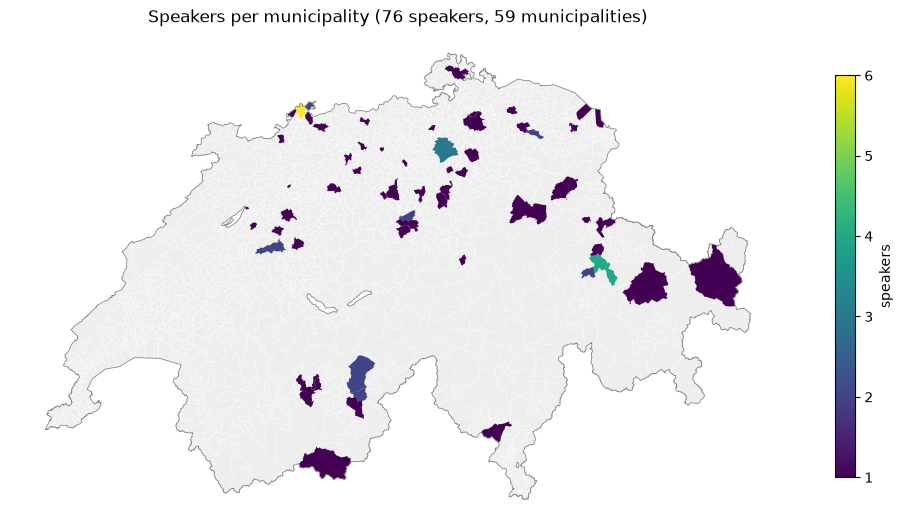

In [6]:
# Speakers per municipality
fig, ax = base_map(f"Speakers per municipality ({int(table.n_speakers.sum())} speakers, {table.bfs_nr.nunique()} municipalities)")
munis[munis.n_speakers > 0].plot(ax=ax, column="n_speakers", cmap="viridis", legend=True,
                                 legend_kwds={"label": "speakers", "shrink": 0.6})
plt.tight_layout()
plt.show()

In [ ]:
# Municipalities coloured by dialect region (with speakers from several regions: the one with most speakers)
speakers = table.groupby(["bfs_nr", "dialect_region"], as_index=False).n_speakers.sum()
main_region = speakers.sort_values("n_speakers").drop_duplicates("bfs_nr", keep="last")
mixed = (speakers.groupby("bfs_nr").size() > 1).sum()
sel = munis.merge(main_region[["bfs_nr", "dialect_region"]], on="bfs_nr")

fig, ax = base_map(f"Speaker municipalities by dialect region ({len(sel)} municipalities, {mixed} with several regions)")
sel.plot(ax=ax, color=sel.dialect_region.map(REGION_COLORS), edgecolor="white", linewidth=0.1)
region_legend(ax, lambda color, region: Patch(facecolor=color, label=region))
plt.tight_layout()
plt.show()

In [ ]:
# Municipality centroids (what the geolocation-aware encoder will use), coloured by dialect region
fig, ax = base_map("Speaker municipalities by dialect region")
points = gpd.GeoDataFrame(table, geometry=gpd.points_from_xy(table.muni_E, table.muni_N), crs=2056)
points.plot(ax=ax, color=points.dialect_region.map(REGION_COLORS), markersize=10 + 15 * points.n_speakers,
            edgecolor="black", linewidth=0.3)
region_legend(ax, lambda color, region: Line2D([], [], marker="o", linestyle="", markerfacecolor=color,
                                               markeredgecolor="black", markeredgewidth=0.3, label=region))
plt.tight_layout()
plt.show()